**Name:** Oshank Karn
**BitsId:** 202605247

# DNN Assignment 2 - Problem 2: Transformer from scratch
**Instruction:** Please upload `Result.csv` and Run with **Restart and Run All** on a T4 GPU (about 20-25 minutes in total).


In [1]:
import os, math, random, time, io, gc, zipfile, urllib.request, contextlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score

os.makedirs('figures', exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)
T0 = time.perf_counter()
print('device:', DEVICE, '| torch', torch.__version__)

device: cuda | torch 2.14.1+cu130


## 1.	Attention from scratch (10 points).
 Write scaled dot-product attention with an optional mask. Unit tests must show that each row of weights sums to 1, that the output matches torch.nn.functional.scaled_dot_product_attention within 1e-5, and that a causal mask gives zero weight to future positions. Include a hand-checkable 3-token example supplied by the instructor, computed by hand and by code.

In [2]:
def scaled_dot_product_attention(q, k, v, mask=None):
    # q: (..., Tq, dk)  k: (..., Tk, dk)  v: (..., Tk, dv)
    # mask: bool, broadcastable to (..., Tq, Tk); True = may attend, False = blocked
    dk = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(dk)      # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    weights = torch.softmax(scores, dim=-1)                # rows sum to 1
    return weights @ v, weights                            # out: (..., Tq, dv)

def causal_mask(T, device=None):
    return torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))   # (T, T), lower triangle True

In [3]:
# Unit tests (direct asserts)
set_seed(0)
q, k, v = torch.randn(2, 4, 6, 8), torch.randn(2, 4, 6, 8), torch.randn(2, 4, 6, 8)   # (B, H, T, dk)

out, w = scaled_dot_product_attention(q, k, v)
assert torch.allclose(w.sum(-1), torch.ones(2, 4, 6), atol=1e-6), 'rows must sum to 1'
assert (out - F.scaled_dot_product_attention(q, k, v)).abs().max() < 1e-5, 'no-mask mismatch'

cm = causal_mask(6)
out_c, w_c = scaled_dot_product_attention(q, k, v, cm)
assert (out_c - F.scaled_dot_product_attention(q, k, v, is_causal=True)).abs().max() < 1e-5, 'causal mismatch'
assert (w_c.masked_fill(cm, 0.0) == 0).all(), 'future positions must get exactly zero weight'
assert torch.allclose(w_c.sum(-1), torch.ones(2, 4, 6), atol=1e-6)
print('attention tests passed')

attention tests passed


### Hand-checkable 3-token example
$d_k=4$ so $\sqrt{d_k}=2$.
$Q=K=\begin{pmatrix}2&0&0&0\\0&2&0&0\\0&0&2&0\end{pmatrix}$, $V=\begin{pmatrix}1&0\\0&1\\1&1\end{pmatrix}$.

Scores $=QK^\top/2$ have 2 on the diagonal and 0 elsewhere, so row 1 of the weights is $\left(\tfrac{e^2}{e^2+2},\tfrac{1}{e^2+2},\tfrac{1}{e^2+2}\right)$ (rows 2 and 3 are the same with the large entry moved), and output row 1 is $\tfrac{1}{e^2+2}\,(e^2+1,\;2)$.

In [4]:
Q = K = torch.tensor([[2., 0, 0, 0], [0, 2., 0, 0], [0, 0, 2., 0]])
V = torch.tensor([[1., 0], [0, 1.], [1., 1.]])
out, w = scaled_dot_product_attention(Q, K, V)
e2 = math.exp(2); S = e2 + 2
W_hand = torch.tensor([[e2 / S if j == i else 1 / S for j in range(3)] for i in range(3)])
V_l = V.tolist()
O_hand = torch.tensor([[sum(W_hand[i, j].item() * V_l[j][c] for j in range(3)) for c in range(2)] for i in range(3)])
assert torch.allclose(w, W_hand, atol=1e-6) and torch.allclose(out, O_hand, atol=1e-6)
print(w); print(out)

tensor([[0.7870, 0.1065, 0.1065],
        [0.1065, 0.7870, 0.1065],
        [0.1065, 0.1065, 0.7870]])
tensor([[0.8935, 0.2130],
        [0.2130, 0.8935],
        [0.8935, 0.8935]])


## 2.	Multi-head attention and encoder block (10 points).
Implement multi-head attention with W_Q, W_K, W_V and W_O and head reshaping, a pre-LayerNorm encoder block with a feed-forward layer of width 4d, residual connections and dropout, and sinusoidal positional encoding. Derive the weight count 4d² + 2•d•d_ff per block and match it to sum(p.numel()). For d = 128 and d_ff = 512 the weights alone come to 196,608 per block; students reconcile the biases and LayerNorm parameters.

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, n_heads, dropout=0.0):
        super().__init__()
        assert d % n_heads == 0
        self.d, self.H, self.dh = d, n_heads, d // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d, d) for _ in range(4))
        self.drop = nn.Dropout(dropout)
    def split(self, x):                       # (B, T, d) -> (B, H, T, dh)
        B, T, _ = x.shape
        return x.view(B, T, self.H, self.dh).transpose(1, 2)
    def forward(self, x, mask=None, return_attn=False):
        q, k, v = self.split(self.W_q(x)), self.split(self.W_k(x)), self.split(self.W_v(x))   # (B, H, T, dh)
        out, w = scaled_dot_product_attention(q, k, v, mask)       # out (B, H, T, dh), w (B, H, T, T)
        out = out.transpose(1, 2).reshape(x.size(0), x.size(1), self.d)   # concat heads: (B, T, d)
        out = self.W_o(self.drop(out))
        return (out, w) if return_attn else out

class SinusoidalPE(nn.Module):
    def __init__(self, d, max_len=4096):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)                                  # (L, 1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))        # (d/2,)
        pe = torch.zeros(max_len, d)
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe)
    def forward(self, x):                      # x: (B, T, d)
        return x + self.pe[:x.size(1)]

class EncoderBlock(nn.Module):
    # pre-LayerNorm: x = x + Drop(MHA(LN(x))); x = x + Drop(FFN(LN(x)))
    def __init__(self, d, n_heads, d_ff=None, dropout=0.1):
        super().__init__()
        d_ff = d_ff or 4 * d
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MultiHeadAttention(d, n_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None, return_attn=False):
        a = self.attn(self.ln1(x), mask, return_attn)
        if return_attn: a, w = a
        x = x + self.drop(a)
        x = x + self.drop(self.ff(self.ln2(x)))
        return (x, w) if return_attn else x

In [6]:
# Tests: shapes, positional encoding values, causality, mask-free permutation behaviour
set_seed(0)
d, H, B, T = 128, 4, 3, 10
x = torch.randn(B, T, d)

mha = MultiHeadAttention(d, H).eval()
y, w = mha(x, causal_mask(T), return_attn=True)
assert y.shape == (B, T, d) and w.shape == (B, H, T, T)

pe = SinusoidalPE(d)
assert torch.allclose(pe.pe[0, 0::2], torch.zeros(d // 2)) and torch.allclose(pe.pe[0, 1::2], torch.ones(d // 2))
assert abs(pe.pe[1, 0].item() - math.sin(1.0)) < 1e-6          # PE(1, 0) = sin(1)

blk = EncoderBlock(d, H, 4 * d, dropout=0.1).eval()
assert blk(x).shape == x.shape

# causal block: changing future tokens must not change earlier outputs
x2 = x.clone(); x2[:, 6:] = torch.randn(B, T - 6, d)
m = causal_mask(T)
assert torch.allclose(blk(x, m)[:, :6], blk(x2, m)[:, :6], atol=1e-5), 'causal leak'
assert not torch.allclose(blk(x)[:, :6], blk(x2)[:, :6], atol=1e-5)   # without a mask it does leak
print('multi-head / PE / block tests passed')

multi-head / PE / block tests passed


In [7]:
# Parameter count: derivation vs sum(p.numel())
d, d_ff = 128, 512
blk = EncoderBlock(d, 4, d_ff)
total = sum(p.numel() for p in blk.parameters())

w_attn = 4 * d * d                  # W_Q, W_K, W_V, W_O weights
w_ff   = 2 * d * d_ff               # two feed-forward matrices
w_only = w_attn + w_ff              # 4d^2 + 2*d*d_ff
b_attn = 4 * d                      # one bias per attention projection
b_ff   = d_ff + d                   # biases of the two FFN linears
ln     = 2 * (2 * d)                # two LayerNorms x (gamma + beta)
print(pd.DataFrame({'part': ['attention weights', 'FFN weights', 'attention biases', 'FFN biases', 'LayerNorm (2x)', 'TOTAL'],
                    'count': [w_attn, w_ff, b_attn, b_ff, ln, w_only + b_attn + b_ff + ln]}))
assert w_only == 196_608
assert total == w_only + b_attn + b_ff + ln == 198_272
print('block parameters:', total)

                part   count
0  attention weights   65536
1        FFN weights  131072
2   attention biases     512
3         FFN biases     640
4     LayerNorm (2x)     512
5              TOTAL  198272
block parameters: 198272


### Results logging
Every run is appended to `results.csv`
RESET_P2_ROWS = True` removes old Problem 2 rows at the start so a clean Run All regenerates them;

In [8]:
RESULT_COLS = ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params',
               'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']
RESULTS_PATH = '../results.csv' if os.path.basename(os.getcwd()) == 'problem2' else 'results.csv'
SEEDS = [0, 1, 2]
RESET_P2_ROWS = True
if RESET_P2_ROWS and os.path.exists(RESULTS_PATH):
    _old = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
    _old[_old.problem != 'P2'].to_csv(RESULTS_PATH, index=False)          # keeps the Problem 1 rows untouched

def log_row(**row):
    pd.DataFrame([{c: row.get(c, '') for c in RESULT_COLS}]).to_csv(
        RESULTS_PATH, mode='a', header=not os.path.exists(RESULTS_PATH), index=False)

def already_done(**key):
    if not os.path.exists(RESULTS_PATH): return False
    df = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
    m = np.ones(len(df), dtype=bool)
    for k, v in key.items(): m &= (df[k] == str(v)).values
    return bool(m.any())

##3.Task A: encoder classifier on the HAR data (10 points).
Reuse the Problem 1 data. Embed each time step (or each patch of 8 steps), add a CLS token, and classify with the encoder. Compare accuracy, parameters and training time with the best Problem 1 model. Ablate positional information: none, sinusoidal and learned.



In [9]:
# ---- data (same files and preprocessing as Problem 1) ----
from pathlib import Path
HAR_ROOT = Path('../problem1/har/UCI HAR Dataset') if Path('../problem1/har/UCI HAR Dataset').is_dir() else Path('har/UCI HAR Dataset')
if not HAR_ROOT.is_dir():
    HAR_ROOT.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve('https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip', 'har.zip')
    zipfile.ZipFile('har.zip').extractall(HAR_ROOT.parent)
    inner = HAR_ROOT.parent / 'UCI HAR Dataset.zip'
    if inner.exists(): zipfile.ZipFile(inner).extractall(HAR_ROOT.parent)
assert HAR_ROOT.is_dir()
CHANNELS = ['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z','total_acc_x','total_acc_y','total_acc_z']
def load_har(split):
    X = np.stack([pd.read_csv(HAR_ROOT/split/'Inertial Signals'/f'{c}_{split}.txt', sep=r'\s+', header=None).values for c in CHANNELS], axis=-1).astype('float32')
    y = np.loadtxt(HAR_ROOT/split/f'y_{split}.txt', dtype=int) - 1
    s = np.loadtxt(HAR_ROOT/split/f'subject_{split}.txt', dtype=int)
    return X, y, s
Xtr_all, ytr_all, subjects = load_har('train'); Xte_np, yte_np, subj_te = load_har('test')
assert Xtr_all.shape == (7352, 128, 9) and Xte_np.shape == (2947, 128, 9) and not (set(subjects) & set(subj_te))

_har_cache = {}
def har_split(seed):
    # subject-wise validation split for this seed; normalisation statistics from the training part only
    if seed not in _har_cache:
        rng = np.random.default_rng(seed)
        val_sub = rng.choice(np.unique(subjects), 4, replace=False); is_val = np.isin(subjects, val_sub)
        Xtr_np, ytr_np, Xva_np, yva_np = Xtr_all[~is_val], ytr_all[~is_val], Xtr_all[is_val], ytr_all[is_val]
        mu = Xtr_np.mean((0, 1), keepdims=True); sd = Xtr_np.std((0, 1), keepdims=True) + 1e-8
        norm = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32, device=DEVICE)
        _har_cache[seed] = (norm(Xtr_np), torch.tensor(ytr_np, device=DEVICE), norm(Xva_np), torch.tensor(yva_np, device=DEVICE),
                            norm(Xte_np), torch.tensor(yte_np, device=DEVICE))
    return _har_cache[seed]

class HARTransformer(nn.Module):
    # x: (B, 128, 9) -> embed (B, 128, d) -> prepend CLS (B, 129, d) -> + positions -> encoder blocks -> CLS -> logits (B, 6)
    def __init__(self, pos_kind='sinusoidal', d=128, heads=4, layers=4, dropout=0.1):
        super().__init__(); self.pos_kind = pos_kind
        self.embed = nn.Linear(9, d); self.cls = nn.Parameter(torch.zeros(1, 1, d)); nn.init.normal_(self.cls, std=0.02)
        self.sin = SinusoidalPE(d, 129) if pos_kind == 'sinusoidal' else None
        self.pos = nn.Parameter(torch.zeros(1, 129, d)) if pos_kind == 'learned' else None
        if self.pos is not None: nn.init.normal_(self.pos, std=0.02)
        self.blocks = nn.ModuleList([EncoderBlock(d, heads, 4 * d, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d); self.head = nn.Linear(d, 6); self.drop = nn.Dropout(dropout)
    def forward(self, x):
        x = self.embed(x); cls = self.cls.expand(x.size(0), -1, -1); x = torch.cat([cls, x], dim=1)
        if self.pos_kind == 'sinusoidal': x = self.sin(x)
        elif self.pos_kind == 'learned': x = x + self.pos[:, :x.size(1)]
        x = self.drop(x)
        for block in self.blocks: x = block(x)
        return self.head(self.norm(x[:, 0]))

def fit_har_transformer(pos_kind, epochs=20, batch_size=128, seed=0, verbose=False):
    Xtr, ytr, Xva, yva, Xte, yte = har_split(seed)
    set_seed(seed); model = HARTransformer(pos_kind).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    best, best_state, epoch_seconds = 0., None, []
    for ep in range(epochs):
        tick = time.perf_counter(); model.train(); order = torch.randperm(len(Xtr), device=DEVICE)
        for ids in order.split(batch_size):
            opt.zero_grad(set_to_none=True); loss = F.cross_entropy(model(Xtr[ids]), ytr[ids]); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        epoch_seconds.append(time.perf_counter() - tick); model.eval()
        with torch.no_grad(): va_acc = (model(Xva).argmax(-1) == yva).float().mean().item()
        if va_acc > best: best = va_acc; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose: print(f'{pos_kind:10s} epoch {ep + 1:02d}/{epochs} val_acc={va_acc:.4f} best={best:.4f}')
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): pred = model(Xte).argmax(-1)
    return dict(test_acc=(pred == yte).float().mean().item(), macro_f1=f1_score(yte.cpu().numpy(), pred.cpu().numpy(), average='macro'),
                params=sum(p.numel() for p in model.parameters()), sec_per_epoch=float(np.mean(epoch_seconds)), best_val=best)
print('Task A data ready:', {k: tuple(v.shape) for k, v in zip(['Xtr', 'ytr', 'Xva', 'yva', 'Xte', 'yte'], har_split(0))})

Task A data ready: {'Xtr': (5886, 128, 9), 'ytr': (5886,), 'Xva': (1466, 128, 9), 'yva': (1466,), 'Xte': (2947, 128, 9), 'yte': (2947,)}


In [10]:
# Task A: 3 positional variants x 3 seeds (each run ~1 minute on a T4); every run is logged to results.csv
for pk in ['none', 'sinusoidal', 'learned']:
    for seed in SEEDS:
        notes = f'taskA_pos_{pk}'
        if already_done(problem='P2', model='Encoder', seed=seed, seq_len=128, notes=notes): continue
        r = fit_har_transformer(pk, seed=seed)
        log_row(problem='P2', model='Encoder', seed=seed, seq_len=128, test_acc=round(r['test_acc'], 4), macro_f1=round(r['macro_f1'], 4),
                params=r['params'], sec_per_epoch=round(r['sec_per_epoch'], 3), notes=notes)
        print(f'pos={pk:10s} seed {seed}: acc {r["test_acc"]:.4f}  F1 {r["macro_f1"]:.4f}  params {r["params"]}  {r["sec_per_epoch"]:.2f}s/epoch  (best val {r["best_val"]:.3f})')

pos=none       seed 0: acc 0.8880  F1 0.8868  params 795526  2.50s/epoch  (best val 0.909)
pos=none       seed 1: acc 0.8809  F1 0.8798  params 795526  2.77s/epoch  (best val 0.892)
pos=none       seed 2: acc 0.8938  F1 0.8934  params 795526  3.17s/epoch  (best val 0.915)
pos=sinusoidal seed 0: acc 0.8989  F1 0.8981  params 795526  3.04s/epoch  (best val 0.922)
pos=sinusoidal seed 1: acc 0.8751  F1 0.8715  params 795526  3.06s/epoch  (best val 0.881)
pos=sinusoidal seed 2: acc 0.8809  F1 0.8785  params 795526  3.10s/epoch  (best val 0.948)
pos=learned    seed 0: acc 0.9287  F1 0.9290  params 812038  3.03s/epoch  (best val 0.924)
pos=learned    seed 1: acc 0.8728  F1 0.8710  params 812038  3.04s/epoch  (best val 0.898)
pos=learned    seed 2: acc 0.9162  F1 0.9159  params 812038  3.09s/epoch  (best val 0.907)


In [26]:
# Task A table: encoder variants next to the Problem 1 recurrent models (read from results.csv when the Problem 1 rows are present)
df = pd.read_csv(RESULTS_PATH)
for c in ['test_acc', 'macro_f1', 'params', 'sec_per_epoch']: df[c] = pd.to_numeric(df[c], errors='coerce')
pm = lambda s, f='{:.4f}': f'{f.format(s.mean())} +- {f.format(s.std(ddof=1))}'
rows = []
for label, sel in [('Encoder, no positions', (df.problem == 'P2') & (df.notes == 'taskA_pos_none')),
                   ('Encoder, sinusoidal', (df.problem == 'P2') & (df.notes == 'taskA_pos_sinusoidal')),
                   ('Encoder, learned', (df.problem == 'P2') & (df.notes == 'taskA_pos_learned')),
                   ('P1 GRU (h=64)', (df.problem == 'P1') & (df.notes == 'har_main') & (df.model == 'GRU')),
                   ('P1 LSTM (h=64)', (df.problem == 'P1') & (df.notes == 'har_main') & (df.model == 'LSTM')),
                   ('P1 GRU (h=128)', (df.problem == 'P1') & (df.notes == 'har_h128') & (df.model == 'GRU')),
                   ('P1 LSTM (h=128)', (df.problem == 'P1') & (df.notes == 'har_h128') & (df.model == 'LSTM'))]:
    g = df[sel]
    if len(g): rows.append((label, len(g), pm(g.test_acc), pm(g.macro_f1), int(g.params.iloc[0]), pm(g.sec_per_epoch, '{:.2f}')))
task_a_table = pd.DataFrame(rows, columns=['model', 'n seeds', 'test acc', 'macro-F1', 'params', 'sec/epoch']); print(task_a_table.to_string(index=False))
if not (df.problem == 'P1').any(): print('(Problem 1 rows are not in this results.csv; add them from your Problem 1 run to compare.)')

                model  n seeds         test acc         macro-F1  params    sec/epoch
Encoder, no positions        3 0.8876 +- 0.0065 0.8867 +- 0.0068  795526 2.81 +- 0.33
  Encoder, sinusoidal        3 0.8850 +- 0.0124 0.8827 +- 0.0138  795526 3.07 +- 0.03
     Encoder, learned        3 0.9059 +- 0.0293 0.9053 +- 0.0304  812038 3.05 +- 0.04
        P1 GRU (h=64)        3 0.8905 +- 0.0133 0.8905 +- 0.0134   14790 0.20 +- 0.01
       P1 LSTM (h=64)        3 0.8892 +- 0.0164 0.8895 +- 0.0170   19590 0.23 +- 0.04
       P1 GRU (h=128)        3 0.9044 +- 0.0129 0.9040 +- 0.0116   54150 0.21 +- 0.01
      P1 LSTM (h=128)        3 0.9031 +- 0.0149 0.9042 +- 0.0145   71942 0.35 +- 0.01


##4.	Task B: character-level causal language model (10 points).
 Train on Tiny Shakespeare (about 1.1 MB, 65 distinct characters) with context 128, d = 128, 4 heads and 4 layers. Report validation loss and bits per character. Generate 500 characters at temperature 0.2, 0.8 and 1.5 with top-k sampling, and describe the differences.

In [12]:
SHAKESPEARE_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not os.path.exists('tinyshakespeare.txt'): urllib.request.urlretrieve(SHAKESPEARE_URL, 'tinyshakespeare.txt')
text = open('tinyshakespeare.txt', encoding='utf-8').read(); chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
V = len(chars); assert V == 65
data = torch.tensor([stoi[c] for c in text], dtype=torch.long); split = int(.9 * len(data))
train_ids, val_ids = data[:split].to(DEVICE), data[split:].to(DEVICE)                  # no shuffling
print(f'corpus chars={len(text):,}; vocabulary={V}; train={len(train_ids):,}; validation={len(val_ids):,}; uniform loss ln 65 = {math.log(65):.3f}')

class CharTransformerLM(nn.Module):
    # idx: (B, T) -> logits (B, T, V); the causal mask stops position t from seeing positions > t
    def __init__(self, vocab_size=V, context=128, d=128, heads=4, layers=4, dropout=.1):
        super().__init__(); self.context = context; self.token = nn.Embedding(vocab_size, d); self.pos = SinusoidalPE(d, context)
        self.blocks = nn.ModuleList([EncoderBlock(d, heads, 4 * d, dropout) for _ in range(layers)]); self.norm = nn.LayerNorm(d); self.lm_head = nn.Linear(d, vocab_size)
    def forward(self, idx):
        B, T = idx.shape; x = self.pos(self.token(idx)); mask = causal_mask(T, device=idx.device)
        for block in self.blocks: x = block(x, mask)
        return self.lm_head(self.norm(x))

def get_batch(source, batch_size=64, context=128):
    starts = torch.randint(len(source) - context - 1, (batch_size,), device=source.device)
    x = torch.stack([source[i:i + context] for i in starts]); y = torch.stack([source[i + 1:i + context + 1] for i in starts]); return x, y

@torch.no_grad()
def estimate_lm_loss(model, source, batches=80):
    model.eval(); losses = []
    for _ in range(batches):
        xb, yb = get_batch(source); losses.append(F.cross_entropy(model(xb).reshape(-1, V), yb.reshape(-1)).item())
    return float(np.mean(losses))

corpus chars=1,115,394; vocabulary=65; train=1,003,854; validation=111,540; uniform loss ln 65 = 4.174


In [13]:
# Main language-model run (single seed)
set_seed(0); CONTEXT = 128; lm = CharTransformerLM().to(DEVICE); optimizer = torch.optim.AdamW(lm.parameters(), lr=3e-4, weight_decay=.01)
MAX_STEPS, EVAL_EVERY, BATCH = 5000, 250, 64; best_val, best_state, lm_log = float('inf'), None, []; started = time.perf_counter()
for step in range(1, MAX_STEPS + 1):
    lm.train(); xb, yb = get_batch(train_ids, BATCH, CONTEXT); optimizer.zero_grad(set_to_none=True)
    loss = F.cross_entropy(lm(xb).reshape(-1, V), yb.reshape(-1)); loss.backward(); torch.nn.utils.clip_grad_norm_(lm.parameters(), 1.0); optimizer.step()
    if step % EVAL_EVERY == 0 or step == 1:
        tr = estimate_lm_loss(lm, train_ids, 30); va = estimate_lm_loss(lm, val_ids, 80); lm_log.append((step, tr, va))
        if va < best_val: best_val = va; best_state = {k: v.detach().cpu().clone() for k, v in lm.state_dict().items()}
        print(f'step {step:5d}: train_loss={tr:.4f} val_loss={va:.4f} nats, val_bpc={va / math.log(2):.4f}')
lm.load_state_dict(best_state); lm.eval()
final_val = estimate_lm_loss(lm, val_ids, 200); lm_params = sum(p.numel() for p in lm.parameters())
print(f'Final validation loss: {final_val:.4f} nats/char; bits per character: {final_val / math.log(2):.4f}; parameters: {lm_params:,}; training time: {(time.perf_counter() - started) / 60:.1f} min')
log_row(problem='P2', model='CharLM', seed=0, seq_len=128, params=lm_params, val_loss_nats=round(final_val, 4),
        bits_per_char=round(final_val / math.log(2), 4), notes='taskB_main_5000steps')

step     1: train_loss=4.0843 val_loss=4.0915 nats, val_bpc=5.9028
step   250: train_loss=2.3693 val_loss=2.3869 nats, val_bpc=3.4436
step   500: train_loss=2.1137 val_loss=2.1578 nats, val_bpc=3.1131
step   750: train_loss=1.9524 val_loss=2.0331 nats, val_bpc=2.9332
step  1000: train_loss=1.8377 val_loss=1.9527 nats, val_bpc=2.8171
step  1250: train_loss=1.7426 val_loss=1.8797 nats, val_bpc=2.7118
step  1500: train_loss=1.6812 val_loss=1.8331 nats, val_bpc=2.6447
step  1750: train_loss=1.6258 val_loss=1.8027 nats, val_bpc=2.6008
step  2000: train_loss=1.5943 val_loss=1.7658 nats, val_bpc=2.5476
step  2250: train_loss=1.5596 val_loss=1.7416 nats, val_bpc=2.5126
step  2500: train_loss=1.5266 val_loss=1.7179 nats, val_bpc=2.4784
step  2750: train_loss=1.5089 val_loss=1.6910 nats, val_bpc=2.4396
step  3000: train_loss=1.4864 val_loss=1.6817 nats, val_bpc=2.4262
step  3250: train_loss=1.4653 val_loss=1.6658 nats, val_bpc=2.4033
step  3500: train_loss=1.4459 val_loss=1.6622 nats, val_bpc=2.

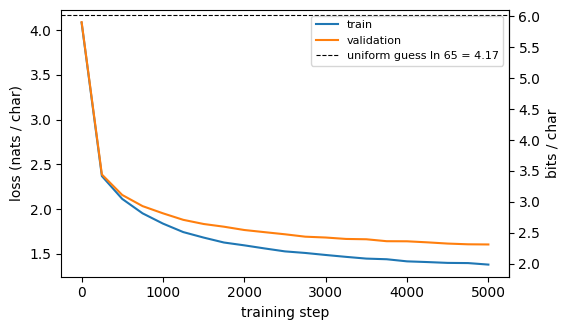

In [14]:
# Learning curve
lg = np.array(lm_log)                                                   # columns: step, train loss, validation loss
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(lg[:, 0], lg[:, 1], label='train'); ax.plot(lg[:, 0], lg[:, 2], label='validation')
ax.axhline(math.log(65), color='k', ls='--', lw=0.8, label='uniform guess ln 65 = 4.17')
ax.set_xlabel('training step'); ax.set_ylabel('loss (nats / char)'); ax.legend(fontsize=8)
sec = ax.secondary_yaxis('right', functions=(lambda v: v / math.log(2), lambda b: b * math.log(2))); sec.set_ylabel('bits / char')
plt.tight_layout(); plt.savefig('figures/lm_learning_curve.png', dpi=150); plt.show()

In [15]:
# Generation: 500 characters at temperature 0.2 / 0.8 / 1.5 with top-k sampling (k = 20), seeded; written to generated_samples.txt
def generate_text(model, prompt='ROMEO:', n_chars=500, temperature=.8, top_k=20):
    model.eval(); idx = torch.tensor([[stoi.get(c, 0) for c in prompt]], device=DEVICE)
    with torch.no_grad():
        for _ in range(n_chars):
            ctx = idx[:, -CONTEXT:]; logits = model(ctx)[:, -1, :] / temperature                         # (1, V) for the last position
            if top_k is not None:
                vals, inds = torch.topk(logits, min(top_k, logits.size(-1))); filt = torch.full_like(logits, float('-inf')); filt.scatter_(1, inds, vals); logits = filt
            nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1); idx = torch.cat([idx, nxt], dim=1)
    return ''.join(itos[int(i)] for i in idx[0].tolist())

PROMPT = 'ROMEO:'
with open('generated_samples.txt', 'w', encoding='utf-8') as f:
    for temp in (0.2, 0.8, 1.5):
        set_seed(1000 + int(temp * 10))
        gen = generate_text(lm, PROMPT, 500, temp, 20)[len(PROMPT):]; assert len(gen) == 500
        f.write(f'===== temperature {temp} (top-k 20, prompt "{PROMPT}", 500 generated characters) =====\n{gen}\n\n')
        print(f'--- temperature {temp} ---\n{gen}\n')

--- temperature 0.2 ---

What thou say the sent of the side of the grace.

LEONTES:
I say the world the live of the fair of the seast,
And that say the sent of the father the stands of my soul.

KING RICHARD III:
The fair of the sent of the king of the country.

KING RICHARD II:
The good of the grace of the stand of the ground
And that thou shalt be shalt be consent the from the false.

KING RICHARD II:
Ay, and the that the sent the for the seast of the sea
The fair of the ground of the sent of the death.

GLOUCESTER:


--- temperature 0.8 ---

Now, she weep an now? what is hath save revenge.

MERCUTIO:
I wantoners the gates: who this son, and since, that
the lie in man the would can respect
In be and possse himself an all thy sleep.
The gods with heaven! But where here, hope
Rave me a thou happy or a man thou wilt it side?
Thou hast thou art share the crowns of thy son;
Never no for the prover of an the hour love to
Arms for the speed? being the king-standing?

ROMEO:
I fear I should 

##5.	Analysis and ablations (10 points).
##(a) Heatmaps of two heads on one sentence, with an interpretation.


In [16]:
import re
train_words = set(re.findall(r"[A-Za-z']+", text[:split].lower()))
blocks = open('generated_samples.txt', encoding='utf-8').read().split('=====')[1:]
for hdr, body in zip(blocks[0::2], blocks[1::2]):
    words = re.findall(r"[A-Za-z']+", body.lower())
    print(hdr.strip().split('(')[0].strip(), '| words:', len(words),
          '| in training text: %.0f%%' % (100 * np.mean([w in train_words for w in words])),
          '| distinct words: %d' % len(set(words)))

temperature 0.2 | words: 105 | in training text: 98% | distinct words: 38
temperature 0.8 | words: 104 | in training text: 96% | distinct words: 75
temperature 1.5 | words: 93 | in training text: 62% | distinct words: 80


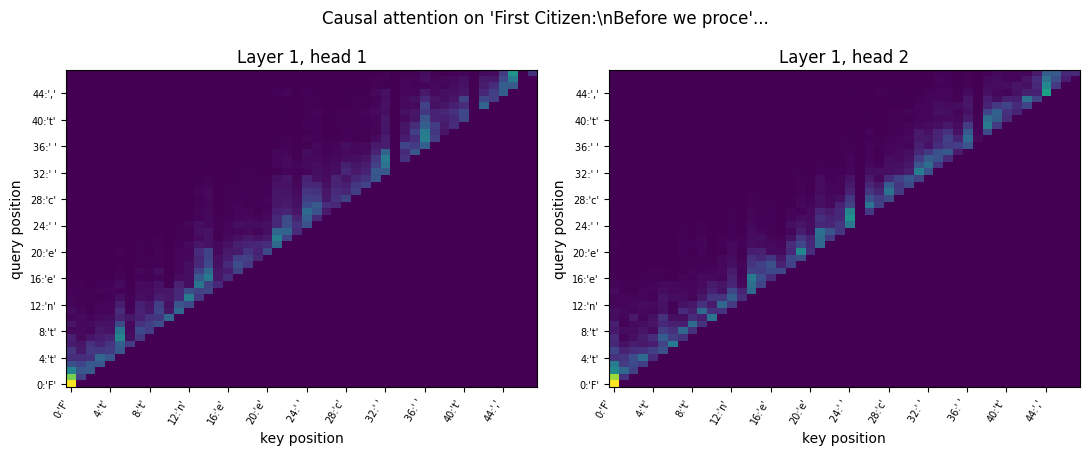

 head  mean weight on self  on previous char  on first char  mass on last 4 chars
    1                0.194             0.210          0.045                 0.708
    2                0.194             0.264          0.057                 0.767
    3                0.132             0.113          0.034                 0.414
    4                0.197             0.234          0.052                 0.713


In [22]:
# 5(a) Two attention heads (layer 1) on one validation-style sentence. Heatmap of the weights, plus numbers describing where each head looks.
lm.eval(); start_char = text.find('First Citizen:'); start_char = max(start_char, 0)
excerpt = text[start_char:start_char + 48]; ids = torch.tensor([[stoi[c] for c in excerpt]], device=DEVICE)
with torch.no_grad():
    x = lm.pos(lm.token(ids)); attn_maps = None
    for li, block in enumerate(lm.blocks):
        x, w = block(x, causal_mask(x.size(1), device=DEVICE), return_attn=True)
        if li == 0: attn_maps = w[0].cpu().numpy()                    # (heads, T, T) of layer 1
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for hi, ax in enumerate(axs):
    ax.imshow(attn_maps[hi], origin='lower', aspect='auto', cmap='viridis', vmin=0)
    ax.set_title(f'Layer 1, head {hi + 1}'); ax.set_xlabel('key position'); ax.set_ylabel('query position')
    ticks = list(range(0, len(excerpt), 4))
    ax.set_xticks(ticks); ax.set_xticklabels([f'{i}:{excerpt[i]!r}' for i in ticks], rotation=60, ha='right', fontsize=7)
    ax.set_yticks(ticks); ax.set_yticklabels([f'{i}:{excerpt[i]!r}' for i in ticks], fontsize=7)
plt.suptitle('Causal attention on ' + repr(excerpt[:30]) + '...'); plt.tight_layout(); plt.savefig('figures/attention_heads.png', dpi=150); plt.show()
assert np.allclose(np.triu(attn_maps, 1), 0)                              # causality: nothing above the diagonal
T_ = attn_maps.shape[1]; q = np.arange(1, T_); rows = []
for h in range(attn_maps.shape[0]):
    A = attn_maps[h]
    rows.append((h + 1, A[q, q].mean(), A[q, q - 1].mean(), A[q, 0].mean(), np.mean([A[i, max(0, i - 3):i + 1].sum() for i in q])))
print(pd.DataFrame(rows, columns=['head', 'mean weight on self', 'on previous char', 'on first char', 'mass on last 4 chars']).round(3).to_string(index=False))

##(b) Heads = 1, 4 and 8 at fixed d.


 heads  seed  steps  val_nats  val_bpc  params  seconds
     1     0   1500    1.8288   2.6383  810049  46.1353
     1     1   1500    1.8059   2.6053  810049  45.8060
     4     0   1500    1.8451   2.6619  810049  57.1979
     4     1   1500    1.8278   2.6370  810049  56.9923
     8     0   1500    1.8509   2.6703  810049  69.1116
     8     1   1500    1.8378   2.6514  810049  69.4166
mean +- std over 2 seeds:
         mean     std
heads                
1      1.8173  0.0162
4      1.8365  0.0122
8      1.8444  0.0093


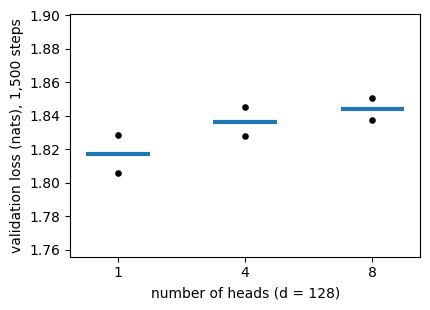

In [18]:
# 5(b) Heads = 1, 4, 8 at fixed d = 128 (head size 128, 32, 16), 4 layers, context 128; 1,500 steps, seeds 0 and 1 per setting
def train_head_variant(heads, seed, steps=1500):
    set_seed(seed); model = CharTransformerLM(vocab_size=V, context=128, d=128, heads=heads, layers=4, dropout=.1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=.01); t0 = time.perf_counter()
    for step in range(steps):
        model.train(); xb, yb = get_batch(train_ids, 64, 128); opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(xb).reshape(-1, V), yb.reshape(-1)); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    val = estimate_lm_loss(model, val_ids, 100)
    return dict(heads=heads, seed=seed, steps=steps, val_nats=val, val_bpc=val / math.log(2), params=sum(p.numel() for p in model.parameters()), seconds=time.perf_counter() - t0)
head_rows = []
for Hh in [1, 4, 8]:
    for sd in (0, 1):
        r = train_head_variant(Hh, sd); head_rows.append(r)
        log_row(problem='P2', model=f'CharLM-h{Hh}', seed=sd, seq_len=128, params=r['params'], val_loss_nats=round(r['val_nats'], 4),
                bits_per_char=round(r['val_bpc'], 4), notes=f'heads_{Hh}_1500steps')
head_results = pd.DataFrame(head_rows); print(head_results.round(4).to_string(index=False))
g = head_results.groupby('heads').val_nats; print('mean +- std over 2 seeds:'); print(pd.DataFrame({'mean': g.mean(), 'std': g.std(ddof=1)}).round(4).to_string())
fig, ax = plt.subplots(figsize=(4.4, 3.2))
for i, Hh in enumerate([1, 4, 8]):
    v = head_results[head_results.heads == Hh].val_nats.values
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color='tab:blue', lw=3); ax.scatter([i] * len(v), v, color='k', s=14, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(['1', '4', '8']); ax.set_xlabel('number of heads (d = 128)'); ax.set_ylabel('validation loss (nats), 1,500 steps')
lo, hi = head_results.val_nats.min(), head_results.val_nats.max(); ax.set_ylim(lo - 0.05, hi + 0.05)
plt.tight_layout(); plt.savefig('figures/heads_ablation.png', dpi=150); plt.show()

##(c) Remove the causal mask and show what happens to training loss and generation.


unmasked step 250: train_loss=2.3679, val_loss=2.3894 (leaky objective)
unmasked step 500: train_loss=0.0532, val_loss=0.0620 (leaky objective)
unmasked step 750: train_loss=0.0234, val_loss=0.0256 (leaky objective)
unmasked step 1000: train_loss=0.0217, val_loss=0.0225 (leaky objective)
unmasked step 1250: train_loss=0.0202, val_loss=0.0213 (leaky objective)
unmasked step 1500: train_loss=0.0193, val_loss=0.0204 (leaky objective)
Unmasked training seconds: 66.0


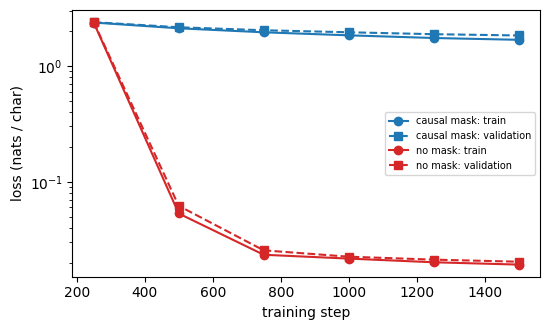

The no-mask losses are not valid next-character losses (future characters leak into the inputs), so they cannot be compared with the causal model as predictions.
Sample from the no-mask model (it is still sampled left to right):
ROMEO:::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::


In [19]:
# 5(c) No causal mask (everything else as the main model; 1,500 steps). Training on a leaky objective: each position can read the character it must predict.
class NoMaskCharTransformerLM(CharTransformerLM):
    def forward(self, idx):
        B, T = idx.shape; x = self.pos(self.token(idx))
        for block in self.blocks: x = block(x, mask=None)
        return self.lm_head(self.norm(x))
set_seed(0); unmasked = NoMaskCharTransformerLM().to(DEVICE); opt_u = torch.optim.AdamW(unmasked.parameters(), lr=3e-4, weight_decay=.01)
mask_log = []; t0 = time.perf_counter()
for step in range(1, 1501):
    unmasked.train(); xb, yb = get_batch(train_ids, 64, 128); opt_u.zero_grad(set_to_none=True)
    loss = F.cross_entropy(unmasked(xb).reshape(-1, V), yb.reshape(-1)); loss.backward(); torch.nn.utils.clip_grad_norm_(unmasked.parameters(), 1.0); opt_u.step()
    if step % 250 == 0:
        tr = estimate_lm_loss(unmasked, train_ids, 50); va = estimate_lm_loss(unmasked, val_ids, 100); mask_log.append((step, tr, va))
        print(f'unmasked step {step}: train_loss={tr:.4f}, val_loss={va:.4f} (leaky objective)')
print('Unmasked training seconds:', round(time.perf_counter() - t0, 1))
log_row(problem='P2', model='CharLM-nomask', seed=0, seq_len=128, params=sum(p.numel() for p in unmasked.parameters()),
        val_loss_nats=round(mask_log[-1][2], 4), bits_per_char=round(mask_log[-1][2] / math.log(2), 4), notes='nomask_1500steps_leaky_not_comparable')
ml = np.array(mask_log); lm_same = lg[(lg[:, 0] >= 250) & (lg[:, 0] <= 1500)]       # masked model at the same steps (from the main run)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(lm_same[:, 0], lm_same[:, 1], 'o-', color='tab:blue', label='causal mask: train'); ax.plot(lm_same[:, 0], lm_same[:, 2], 's--', color='tab:blue', label='causal mask: validation')
ax.plot(ml[:, 0], ml[:, 1], 'o-', color='tab:red', label='no mask: train'); ax.plot(ml[:, 0], ml[:, 2], 's--', color='tab:red', label='no mask: validation')
ax.set_yscale('log'); ax.set_xlabel('training step'); ax.set_ylabel('loss (nats / char)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/no_mask.png', dpi=150); plt.show()
print('The no-mask losses are not valid next-character losses (future characters leak into the inputs), so they cannot be compared with the causal model as predictions.')
set_seed(2000); print('Sample from the no-mask model (it is still sampled left to right):'); print(generate_text(unmasked, PROMPT, 500, .8, 20))

##(d) Measure time and memory at context 64, 128, 256 and 512 and relate the growth to O(n²•d).

 context  batch_size  mean_step_s  std_step_s  step_memory_MiB
      64          16      0.01230     0.00099         41.73828
     128          16      0.01186     0.00080         91.22266
     256          16      0.01998     0.00064        225.56934
     512          16      0.05701     0.00038        675.03809
mean_step_s: fitted exponent over all contexts 0.74; between 256 and 512 1.51  (pure n^2 would be 2)
step_memory_MiB: fitted exponent over all contexts 1.34; between 256 and 512 1.58  (pure n^2 would be 2)


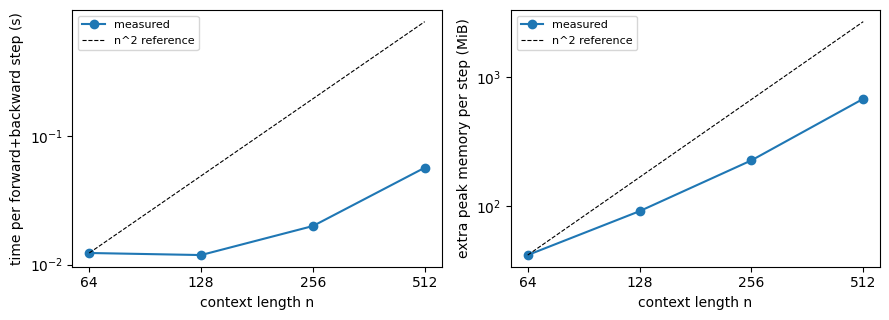

Attention scores are (batch, heads, n, n), so score storage and the QK^T / weights-V products grow as n^2 (times head size); the rest of the model grows linearly in n, so small contexts show a smaller exponent than 2.


In [20]:
# 5(d) Time and memory against context length: one forward+backward step, batch 16, d = 128, 4 heads, 4 layers.
# Warm-up first (the first call includes CUDA start-up); memory is the extra peak above what the live models/tensors already hold.
def benchmark_context(n, repeats=20, warmup=10, batch=16):
    model = CharTransformerLM(vocab_size=V, context=max(512, n), d=128, heads=4, layers=4, dropout=.1).to(DEVICE)
    xb, yb = get_batch(train_ids, batch, n)
    def step():
        model.train(); model.zero_grad(set_to_none=True); F.cross_entropy(model(xb).reshape(-1, V), yb.reshape(-1)).backward()
    for _ in range(warmup): step()
    model.zero_grad(set_to_none=True); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.synchronize(); base = torch.cuda.memory_allocated(DEVICE); torch.cuda.reset_peak_memory_stats(DEVICE)
    step()
    peak = (torch.cuda.max_memory_allocated(DEVICE) - base) / 1024 ** 2 if DEVICE.type == 'cuda' else float('nan')
    ts = []
    for _ in range(repeats):
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        a = time.perf_counter(); step()
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        ts.append(time.perf_counter() - a)
    del model, xb, yb; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return dict(context=n, batch_size=batch, mean_step_s=float(np.mean(ts)), std_step_s=float(np.std(ts)), step_memory_MiB=peak)
bench = pd.DataFrame([benchmark_context(n) for n in [64, 128, 256, 512]]); print(bench.round(5).to_string(index=False))
ns = bench.context.values
for col in ['mean_step_s', 'step_memory_MiB']:
    s_all = np.polyfit(np.log(ns), np.log(bench[col].values), 1)[0]; s_hi = np.polyfit(np.log(ns[-2:]), np.log(bench[col].values[-2:]), 1)[0]
    print(f'{col}: fitted exponent over all contexts {s_all:.2f}; between 256 and 512 {s_hi:.2f}  (pure n^2 would be 2)')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for a_, col, lab in zip(ax, ['mean_step_s', 'step_memory_MiB'], ['time per forward+backward step (s)', 'extra peak memory per step (MiB)']):
    a_.loglog(ns, bench[col], 'o-', label='measured'); a_.loglog(ns, bench[col].iloc[0] * (ns / ns[0]) ** 2, 'k--', lw=0.8, label='n^2 reference')
    a_.set_xlabel('context length n'); a_.set_ylabel(lab); a_.set_xticks(ns); a_.set_xticklabels(ns); a_.legend(fontsize=8)
    a_.minorticks_off()
plt.tight_layout(); plt.savefig('figures/time_memory_vs_context.png', dpi=150); plt.show()
print('Attention scores are (batch, heads, n, n), so score storage and the QK^T / weights-V products grow as n^2 (times head size); the rest of the model grows linearly in n, so small contexts show a smaller exponent than 2.')

## Summary of logged Problem 2 runs

In [21]:
res = pd.read_csv(RESULTS_PATH); print(res[res.problem == 'P2'].to_string(index=False))
print(f'\nTotal notebook run time: {(time.perf_counter() - T0) / 60:.1f} min on {DEVICE}')

problem         model  seed  seq_len  test_acc  macro_f1  test_mse  params  sec_per_epoch  val_loss_nats  bits_per_char                                 notes
     P2       Encoder     0      128    0.8880    0.8868       NaN  795526          2.502            NaN            NaN                        taskA_pos_none
     P2       Encoder     1      128    0.8809    0.8798       NaN  795526          2.769            NaN            NaN                        taskA_pos_none
     P2       Encoder     2      128    0.8938    0.8934       NaN  795526          3.167            NaN            NaN                        taskA_pos_none
     P2       Encoder     0      128    0.8989    0.8981       NaN  795526          3.040            NaN            NaN                  taskA_pos_sinusoidal
     P2       Encoder     1      128    0.8751    0.8715       NaN  795526          3.057            NaN            NaN                  taskA_pos_sinusoidal
     P2       Encoder     2      128    0.8809    0.